# Porównanie gęstości siatek

Notebook generuje cztery warianty tej samej geometrii, zapisuje każdy do osobnego katalogu w `results/mesh_comparison/` i pokazuje ich triangulację.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from mpi4py import MPI
from dolfinx import plot as dolfinx_plot
from dolfinx.io import gmsh as dolfinx_gmsh

from src.config import geometry
from src.mesh import MagnetronMesh, MeshSettings
from src.magnetostatics import MagnetostaticSimulation
from src.visualization import plot_magnetic_field


In [ ]:
RESULTS_DIR = Path("results/mesh_comparison")

MESH_CASES = {
    "coarse": MeshSettings(min_size=0.10, max_size=2.00),
}

mesh_paths = {}
for name, settings in MESH_CASES.items():
    case_dir = RESULTS_DIR / name
    mesh_paths[name] = MagnetronMesh(geometry, settings).generate(
        case_dir / "mesh.msh"
    )
    print(f"{name}: {mesh_paths[name]}")


Info    : Meshing 1D...nts - Adding holes                                                                                              
Info    : [  0%] Meshing curve 15 (Line)
Info    : [ 10%] Meshing curve 19 (Line)
Info    : [ 10%] Meshing curve 23 (Line)
Info    : [ 20%] Meshing curve 24 (Line)
Info    : [ 20%] Meshing curve 25 (Line)
Info    : [ 20%] Meshing curve 26 (Line)
Info    : [ 30%] Meshing curve 27 (Line)
Info    : [ 30%] Meshing curve 28 (Line)
Info    : [ 40%] Meshing curve 29 (Line)
Info    : [ 40%] Meshing curve 30 (Line)
Info    : [ 40%] Meshing curve 31 (Line)
Info    : [ 50%] Meshing curve 32 (Line)
Info    : [ 50%] Meshing curve 33 (Line)
Info    : [ 60%] Meshing curve 34 (Line)
Info    : [ 60%] Meshing curve 35 (Line)
Info    : [ 60%] Meshing curve 36 (Line)
Info    : [ 70%] Meshing curve 37 (Line)
Info    : [ 70%] Meshing curve 38 (Line)
Info    : [ 70%] Meshing curve 39 (Line)
Info    : [ 80%] Meshing curve 40 (Line)
Info    : [ 80%] Meshing curve 41 (Line)
Inf

Info    : Reading 'results/mesh_comparison/coarse/mesh.msh'...
Info    : 54 entities
Info    : 1654 nodes
Info    : 3166 elements
Info    : Done reading 'results/mesh_comparison/coarse/mesh.msh'


ValueError: zip() argument 2 is shorter than argument 1

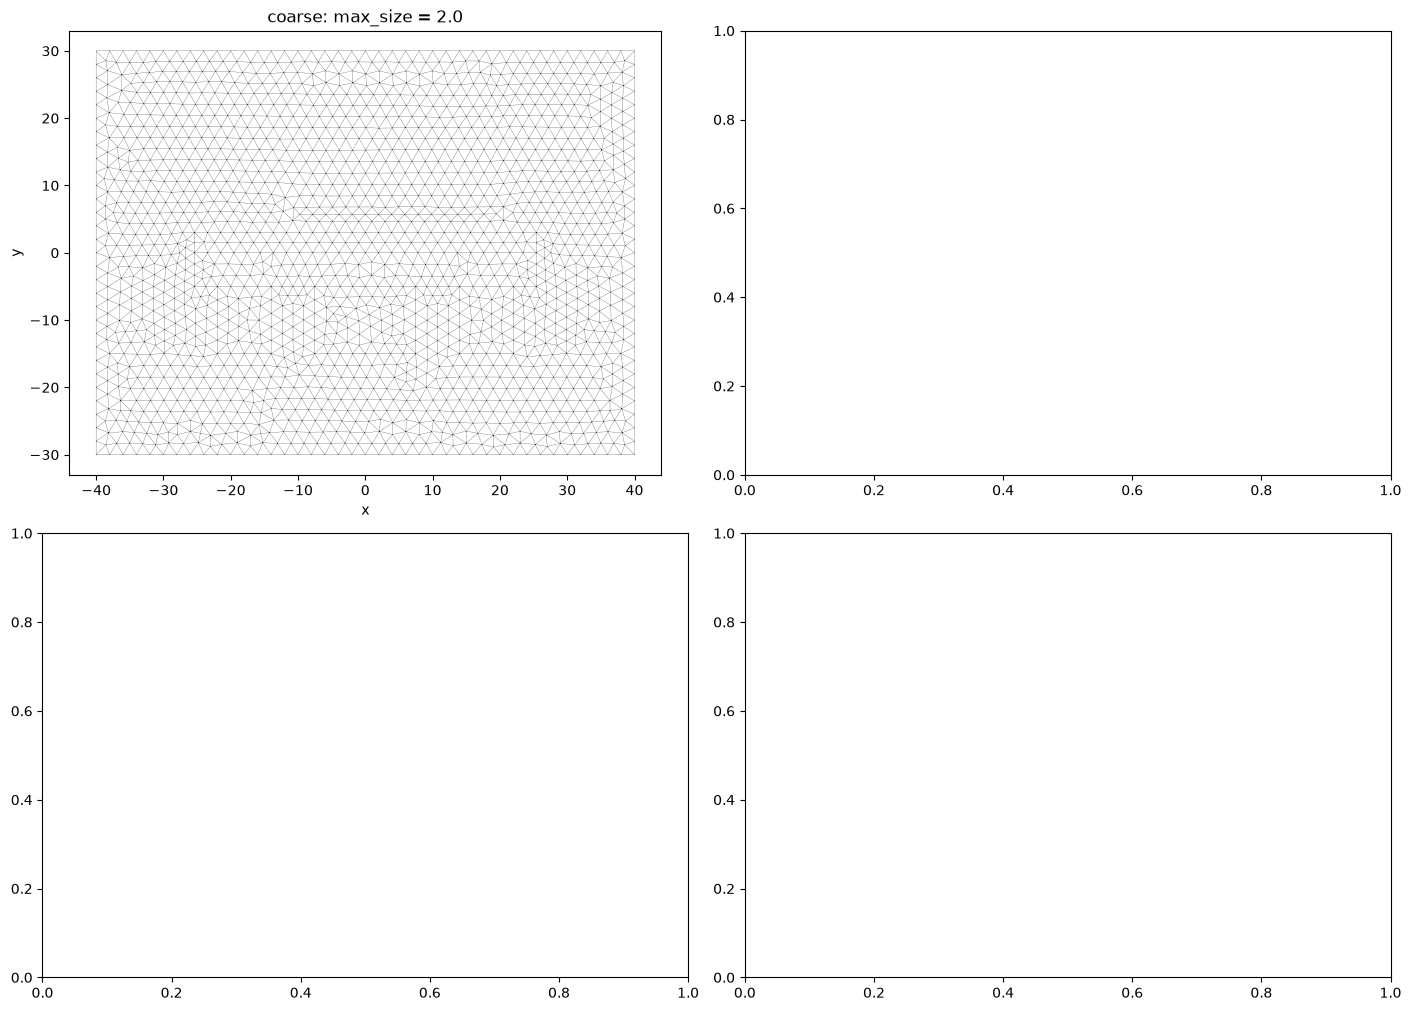

In [12]:
def triangulation_from_mesh(mesh_path):
    """Read a 2D DOLFINx mesh and convert its cells for Matplotlib."""
    mesh_data = dolfinx_gmsh.read_from_msh(
        str(mesh_path), MPI.COMM_WORLD, gdim=2
    )
    cells, _, points = dolfinx_plot.vtk_mesh(mesh_data.mesh)
    triangles = cells.reshape(-1, 4)[:, 1:]
    return mtri.Triangulation(points[:, 0], points[:, 1], triangles)

figure, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for axis, (name, settings) in zip(axes.flat, MESH_CASES.items(), strict=True):
    triangulation = triangulation_from_mesh(mesh_paths[name])
    axis.triplot(triangulation, color="black", linewidth=0.15)
    axis.set_aspect("equal")
    axis.set_title(f"{name}: max_size = {settings.max_size}")
    axis.set_xlabel("x")
    axis.set_ylabel("y")

mesh_plot_path = RESULTS_DIR / "mesh_comparison.png"
figure.savefig(mesh_plot_path, dpi=200)
plt.show()
print(f"Saved mesh comparison: {mesh_plot_path}")


## Opcjonalnie: oblicz i zapisz pole dla każdego wariantu

Ustaw `RUN_SOLVERS = True`, aby wykonać cztery obliczenia. Dla każdego wariantu zapiszą się `fields.xdmf`, `simulation.json` i `field.png`.

In [13]:
RUN_SOLVERS = True

if RUN_SOLVERS:
    if MPI.COMM_WORLD.size != 1:
        raise RuntimeError("Field plots require one MPI process.")

    field_plot_paths = {}
    for name, mesh_path in mesh_paths.items():
        case_dir = RESULTS_DIR / name
        result = MagnetostaticSimulation(mesh_path).solve(case_dir)
        field_plot_paths[name] = plot_magnetic_field(
            result, case_dir / "field.png"
        )
        print(f"Solved and plotted: {name}")


Info    : Reading 'results/mesh_comparison/coarse/mesh.msh'...
Info    : 54 entities
Info    : 1654 nodes
Info    : 3166 elements
Info    : Done reading 'results/mesh_comparison/coarse/mesh.msh'
Solved and plotted: coarse


ValueError: zip() argument 2 is shorter than argument 1

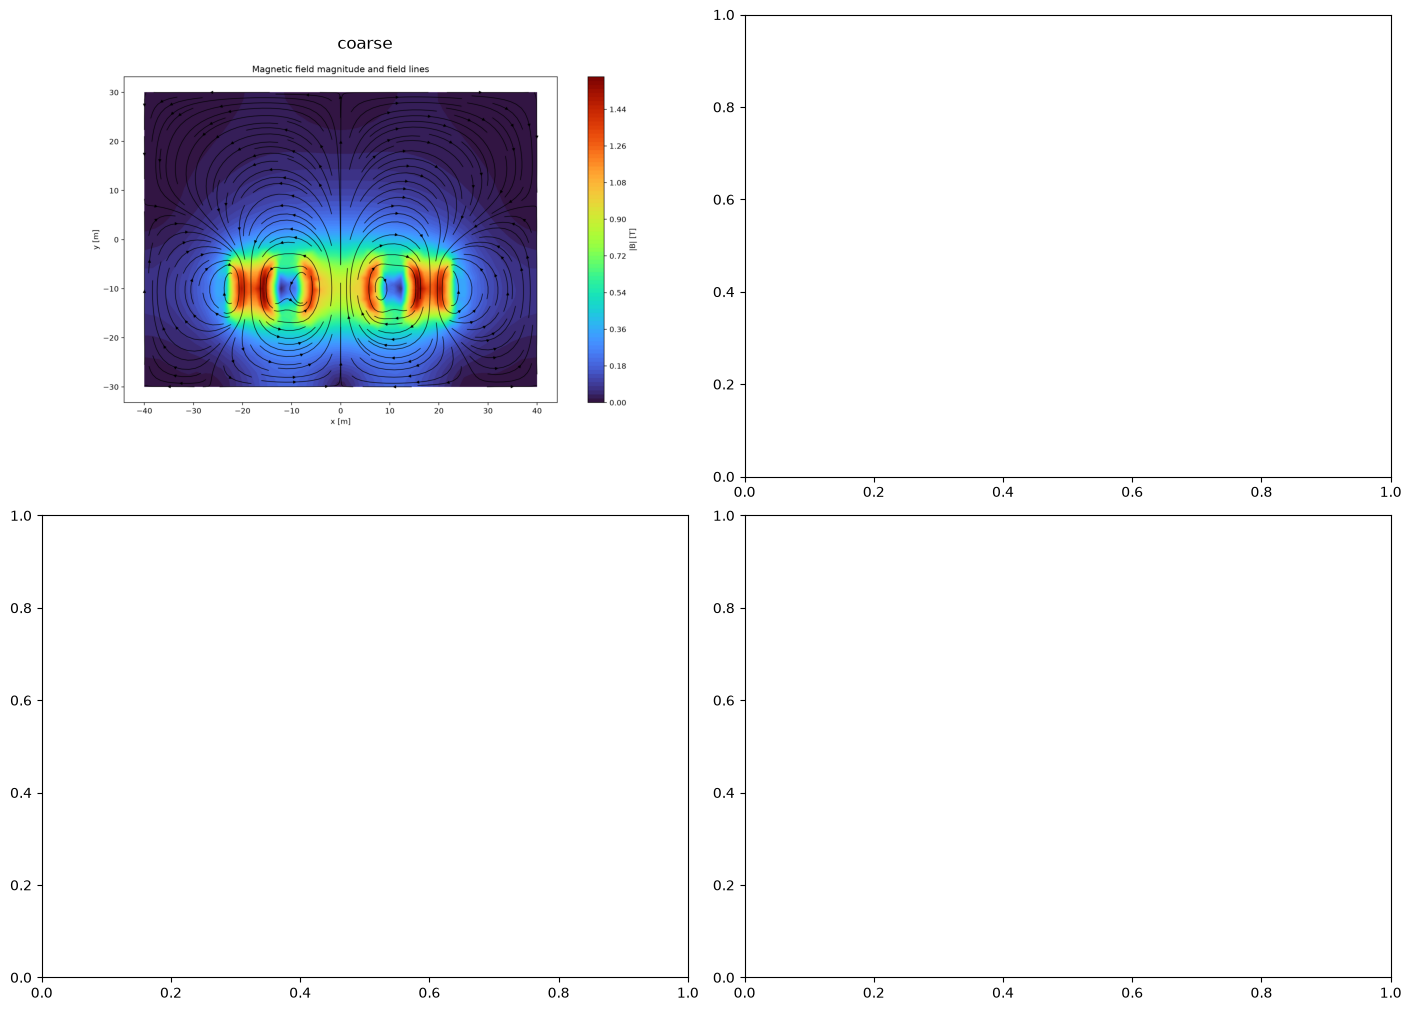

In [14]:
if RUN_SOLVERS:
    figure, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    for axis, (name, image_path) in zip(
        axes.flat, field_plot_paths.items(), strict=True
    ):
        axis.imshow(plt.imread(image_path))
        axis.set_title(name)
        axis.axis("off")

    field_comparison_path = RESULTS_DIR / "field_comparison.png"
    figure.savefig(field_comparison_path, dpi=200)
    plt.show()
    print(f"Saved field comparison: {field_comparison_path}")
